# Calibration 3 — Nhân quả trong đuôi theo thời gian (Granger trong đuôi)

EASE chỉ dùng quan hệ **đồng thời**. Notebook này hỏi câu hỏi **có thời gian**: cú sốc cực trị của mã $X$ hôm nay có làm mã $Y$ dễ cực trị trong $p$ phiên tới
hơn mức thông thường không — sau khi loại các phiên mà chính $Y$ hoặc thị trường đã cực trị?

**Hệ số** (theo Bodik & Pasche 2024, "Granger causality in extremes", arXiv:2407.09632; bản đơn giản hoá — điều kiện chỉ xét phiên $t$):
$$\hat\Gamma_{X\to Y}(p) = \frac{1}{|S|}\sum_{t\in S}\max_{1\le h\le p}\tilde F_Y(Y_{t+h}),\qquad \tilde F_Y(y) = \hat F_Y(y)\,\mathbb 1\{\hat F_Y(y)\ge \tfrac12\},$$
$S$: $k$ phiên có $X_t$ cực trị trong số các phiên "sạch" ($\hat F_Y(Y_t) \le 0{,}8$ và thị trường không chứa $X, Y$ có $\hat F_M(M_t) \le 0{,}9$).
Mức nền $b$ = cùng đại lượng trên mọi phiên sạch; $\Delta = \hat\Gamma - b$. Kiểm định $H_0: \Delta \le 0$ bằng **moving-block bootstrap** (khối $\lceil\sqrt n\rceil$),
hiệu chỉnh **Benjamini–Hochberg** trên 3.540 cặp. Đuôi dưới (cú sập) là trọng tâm; đuôi trên để so sánh.

## 0. Thiết lập

In [1]:
import sys, warnings
from pathlib import Path

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "sql").is_dir() and (p / "src").is_dir())
sys.path.insert(0, str(ROOT / "src"))
warnings.filterwarnings("ignore", category=FutureWarning)

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import eda_utils as U
import causal_tail as CT
import causal_baselines as CB
import tail_preprocessing as TP

U.apply_publication_style()
pd.set_option("display.float_format", "{:,.3f}".format)
SYMBOLS, COL, PAL = U.SYMBOLS, U.SYMBOL_COLORS, U.PALETTE
FOLDER = "calibration"                      # hình → report/figure/processing, bảng → report/table/processing
METHOD_COLORS = {"EASE": PAL["blue_main"], "Pairwise LiNGAM": PAL["red_strong"], "ICA-LiNGAM": PAL["green_3"],
                 "Rank PC": PAL["violet"], "Ngẫu nhiên": PAL["neutral"]}

import warnings
warnings.filterwarnings("ignore", category=RuntimeWarning)
import validation as V
import calibration as C
from scipy import stats
from joblib import Parallel, delayed
P = len(SYMBOLS)
OFF = ~np.eye(P, dtype=bool)
Z = pd.read_parquet(ROOT / "data" / "processed" / "garch_std_resid_market.parquet")
z = Z[SYMBOLS]
n, K = len(z), CT.default_k(len(z))
NU_CAL = 0.35                     # ν chọn ở Calibration 01 (mô phỏng hiệu chỉnh + độ ổn định)
KC = CT.default_k(n, NU_CAL)
print(f"n = {n} phiên, {P} mã, k(ν=0,4) = {K}, k hiệu chỉnh (ν={NU_CAL}) = {KC}")

SECTOR = U.SECTOR
B_BOOT = 300

n = 2103 phiên, 60 mã, k(ν=0,4) = 21, k hiệu chỉnh (ν=0.35) = 14


## 1. Kiểm tra kích thước kiểm định (size) dưới $H_0$

**Ngưỡng hiệu chỉnh bằng mô phỏng.** Nếu kích thước kiểm định bootstrap lệch, dùng thay thế: cặp thật được coi là có tín hiệu khi $\Delta$ vượt
phân vị 99,9% của $\Delta$ dưới $H_0$ (gộp 10.620 cặp mô phỏng của cùng độ trễ) — kỳ vọng ≈ 3,5 cặp sai trên 3.540 cặp.

**Các bước:** với mỗi độ trễ $p \in \{1, 3, 5\}$: 3 bộ dữ liệu từ mô hình một nhân tố **không có độ trễ** (không có nhân quả theo thời gian), cùng $n$,
chạy đủ 3.540 cặp; tỷ lệ $p < 0{,}05$ phải ≈ 5% và số cặp qua FDR 10% phải ≈ 0. $k = \lfloor n^{0{,}35}\rfloor = 14$ (Calibration 01; gần mặc định $n^{1/3}$ của bài báo).

In [2]:
gp = pd.read_csv(ROOT / "report" / "table" / "processing" / "02_garch_params.csv", index_col=0, encoding="utf-8-sig")
NU = float(gp["nu"].mean()); lam = V.fit_one_factor(z).to_numpy()
size, null_delta = [], {}
for lag in (1, 3, 5):
    for rep in range(3):
        X = pd.DataFrame(V.simulate_factor_scm(n, lam, NU, rng=np.random.default_rng(500 + rep)), columns=SYMBOLS)
        G0 = C.extremal_granger_matrix(X, k=KC, lag=lag, tail="lower", B=B_BOOT, seed=rep)
        null_delta.setdefault(lag, []).extend(G0.delta.dropna().tolist())
        size.append({"tre": lag, "lan": rep, "ty_le_p<0,05": (G0.p < 0.05).mean(), "so_cap_q<0,1": int((G0.q < 0.1).sum())})
size = pd.DataFrame(size).set_index(["tre", "lan"])
# Ngưỡng hiệu chỉnh bằng mô phỏng: phân vị 99,9% của Δ dưới H0 (1.140 cặp × cấu hình) — dùng thay p bootstrap khi size lệch
null_thr = {lag: float(np.quantile(v, 0.999)) for lag, v in null_delta.items()}
print("Ngưỡng Δ (phân vị 99,9% dưới H0):", {k: round(v, 3) for k, v in null_thr.items()})
U.save_table(size, "03_size_check", FOLDER)
size

Ngưỡng Δ (phân vị 99,9% dưới H0): {1: 0.324, 3: 0.185, 5: 0.109}


ty_le_p<0,05  so_cap_q<0,1
tre lan                            
1   0           0.068             0
    1           0.069             0
    2           0.086             0
3   0           0.143           305
    1           0.149           361
    2           0.152           377
5   0           0.194           395
    1           0.174           361
    2           0.194           392

### Phân tích
- **Trễ 1:** tỷ lệ $p < 0{,}05$ dưới H0 là 6,8–8,6% (danh nghĩa 5%), **0 phát hiện sai qua FDR** — kiểm định dùng được, hơi dễ dãi.
- **Trễ 3 và 5: kích thước lệch rất nặng** — 14–19% cặp có $p < 0{,}05$ và **305–395 phát hiện sai qua FDR 10%** (trên 3.540 cặp) dù dữ liệu không có quan hệ trễ nào. Với thống kê là max của
  nhiều phiên tương lai, bootstrap khối đánh giá thấp phương sai. p-value bootstrap cho trễ > 1 **không dùng được**; thay bằng ngưỡng hiệu chỉnh bằng mô phỏng:
  $\Delta$ vượt phân vị 99,9% dưới H0 (0,32 / 0,19 / 0,11 cho trễ 1 / 3 / 5; kỳ vọng ~3,5 cặp sai mỗi cấu hình).

## 2. Dữ liệu thật: đuôi dưới, độ trễ 1, 3, 5 phiên

**Tính gì:** $\hat\Gamma$, $b$, $\Delta$, p, q cho 3.540 cặp với $p \in \{1, 3, 5\}$ (đuôi dưới) và $p = 1$ (đuôi trên). Hình: ma trận $\Delta$ (đuôi dưới, $p=1$)
và phân phối p-value cho từng cấu hình.

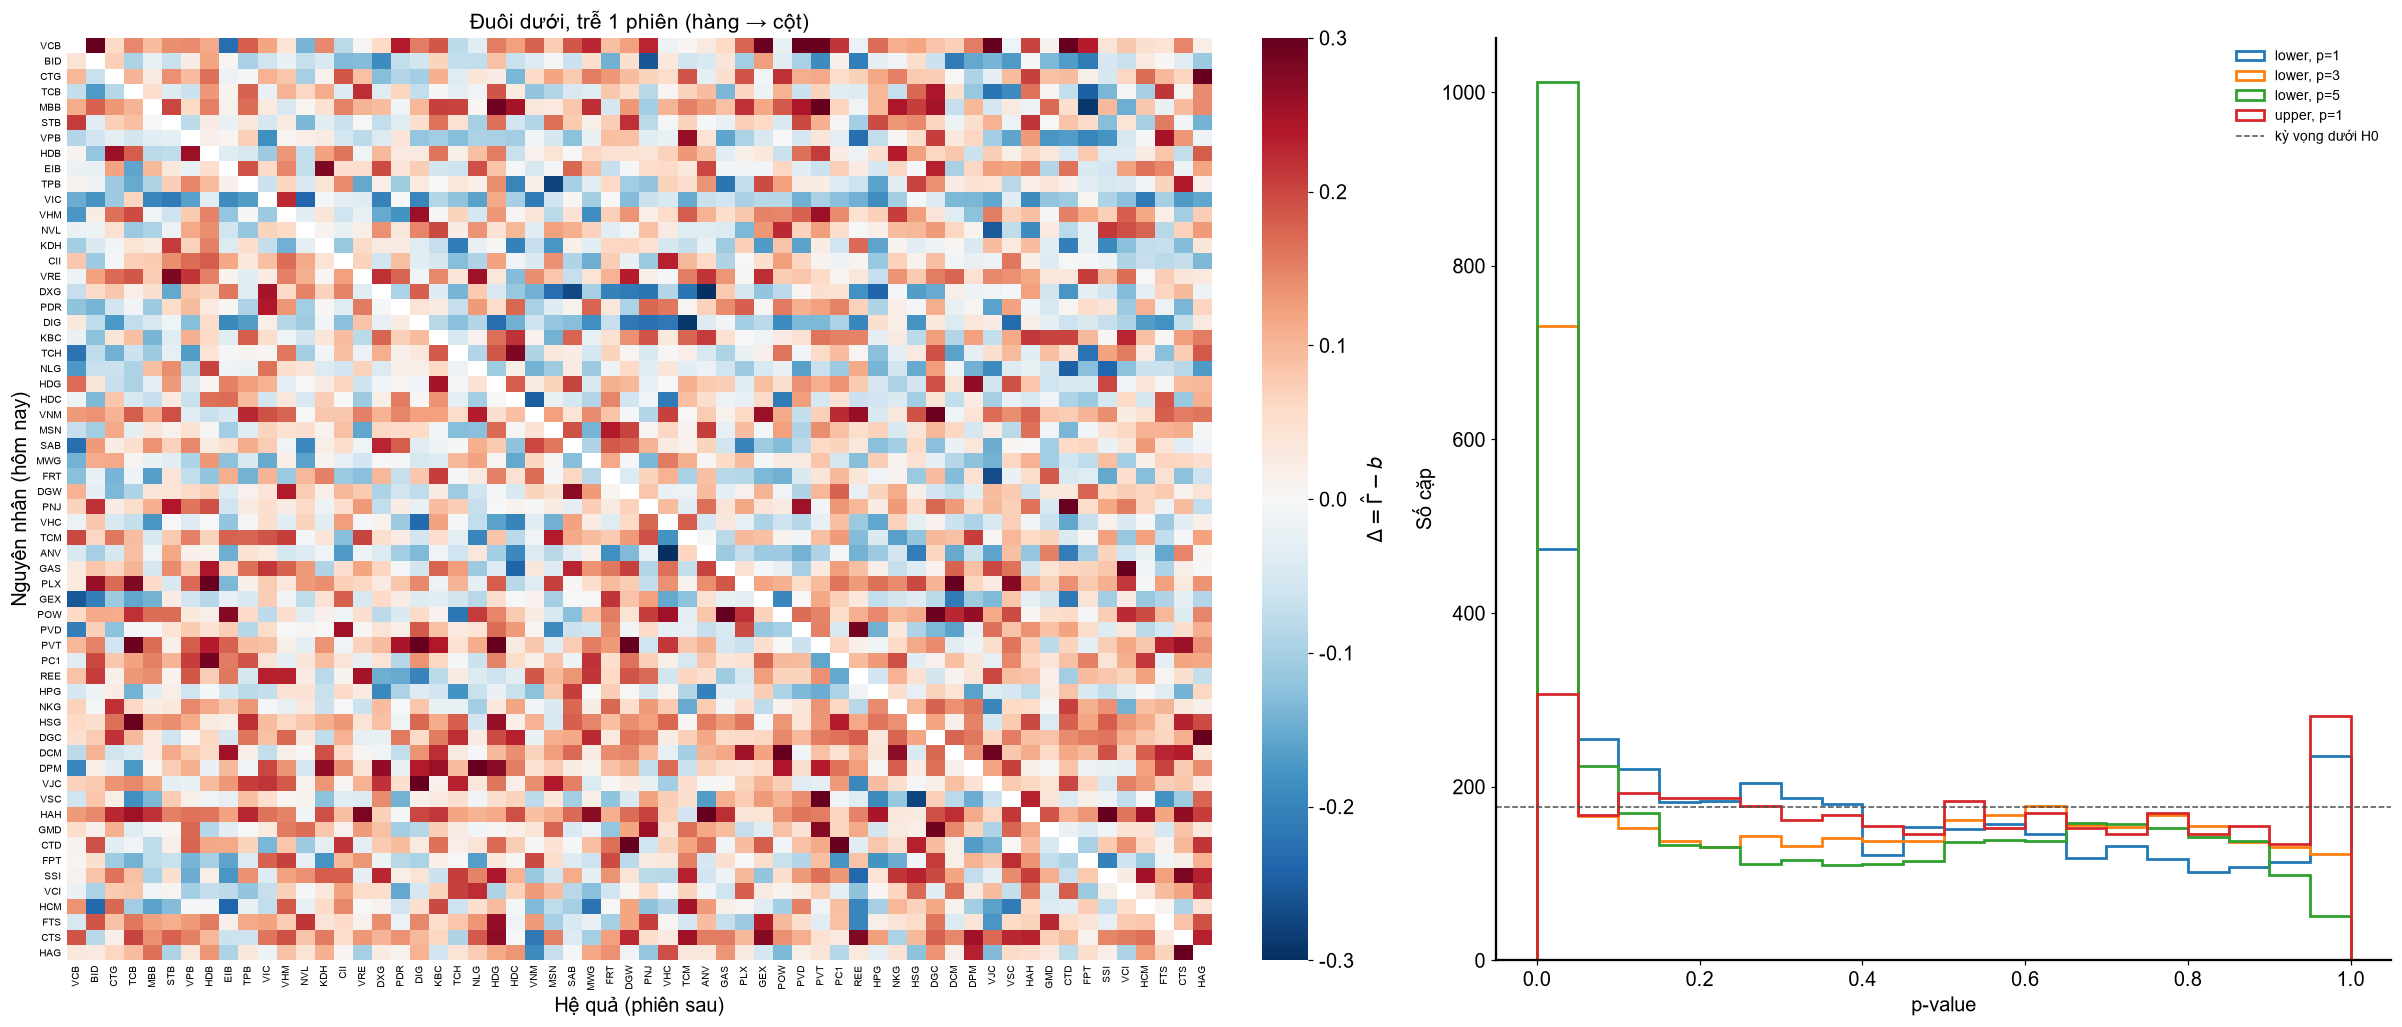

,"ty_le_p<0,05","so_cap_q<0,1",so_cap_vuot_nguong_H0,Delta_TB,so_cap_quy_tac_cuc_tri
"lower, p=1",0.134,131.000,7.000,0.033,13.000
"lower, p=3",0.206,530.000,22.000,0.015,105.000
"lower, p=5",0.286,772.000,29.000,0.016,116.000
"upper, p=1",0.087,0.000,NaN,0.008,6.000


In [3]:
configs = [("lower", 1), ("lower", 3), ("lower", 5), ("upper", 1)]
res = {}
for tail, lag in configs:
    G = C.extremal_granger_matrix(z, k=KC, lag=lag, tail=tail, B=B_BOOT, seed=lag * 10 + (tail == "upper"))
    res[(tail, lag)] = G
    U.save_table(G.set_index(["cause", "effect"]), f"03_granger_{tail}_lag{lag}", FOLDER)
summary = pd.DataFrame({f"{t}, p={l}": {"ty_le_p<0,05": (G.p < 0.05).mean(), "so_cap_q<0,1": int((G.q < 0.1).sum()),
                                        "so_cap_vuot_nguong_H0": int((G.delta > null_thr[l]).sum()) if t == "lower" else np.nan,
                                        "Delta_TB": G.delta.mean(), "so_cap_quy_tac_cuc_tri": int(G.extreme_rule.sum())}
                        for (t, l), G in res.items()}).T
U.save_table(summary, "03_granger_summary", FOLDER)

G1 = res[("lower", 1)]
Dm = G1.pivot(index="cause", columns="effect", values="delta").reindex(index=SYMBOLS, columns=SYMBOLS)
fig, axes = plt.subplots(1, 2, figsize=(22, 9.5), gridspec_kw={"width_ratios": [1.4, 1]})
U.make_heatmap(axes[0], Dm, cmap="RdBu_r", vmin=-0.3, vmax=0.3, fmt=None, tick_fontsize=6.5, cbar_label=r"$\Delta = \hat\Gamma - b$",
               title="Đuôi dưới, trễ 1 phiên (hàng → cột)")
axes[0].set_xlabel("Hệ quả (phiên sau)"); axes[0].set_ylabel("Nguyên nhân (hôm nay)")
for (t, l), G in res.items():
    axes[1].hist(G.p, bins=np.linspace(0, 1, 21), histtype="step", lw=1.8, label=f"{t}, p={l}")
axes[1].axhline(len(G1) / 20, color=PAL["gray_dark"], ls="--", lw=1, label="kỳ vọng dưới H0")
axes[1].set_xlabel("p-value"); axes[1].set_ylabel("Số cặp"); axes[1].legend(fontsize=9)
U.finalize_figure(fig, "03_granger_real", folder=FOLDER); plt.show()
summary.round(3)

In [4]:
# Tổng hợp theo ngành (đuôi dưới, trễ 1): Δ trung bình từ ngành nguồn tới ngành đích
G1s = G1.assign(nganh_nguon=G1.cause.map(SECTOR), nganh_dich=G1.effect.map(SECTOR))
blk = G1s.groupby(["nganh_nguon", "nganh_dich"]).delta.mean().unstack().reindex(index=U.SECTORS, columns=U.SECTORS)
U.save_table(blk, "03_granger_sector_blocks", FOLDER)
strong = pd.concat([res[("lower", l)].assign(tre=l)[lambda d: d.delta > null_thr[l]] for l in (1, 3, 5)])
U.save_table(strong.set_index(["tre", "cause", "effect"]), "03_granger_beyond_null", FOLDER)
print("Cặp có Δ vượt ngưỡng 99,9% dưới H0 (đuôi dưới):")
strong.sort_values("delta", ascending=False)[["tre", "cause", "effect", "gamma", "baseline", "delta", "p", "q"]].head(15).round(3)

Cặp có Δ vượt ngưỡng 99,9% dưới H0 (đuôi dưới):


,tre,cause,effect,gamma,baseline,delta,p,q
2713,1,DGC,HAG,0.784,0.372,0.411,0.003,0.090
2060,1,GAS,VCI,0.747,0.378,0.369,0.003,0.090
3097,1,CTD,DGW,0.743,0.385,0.359,0.003,0.090
2323,1,PVT,HDG,0.721,0.369,0.352,0.003,0.090
38,1,VCB,PVT,0.712,0.375,0.338,0.003,0.090
2850,1,VJC,DIG,0.700,0.366,0.334,0.003,0.090
2319,1,PVT,DIG,0.696,0.366,0.329,0.003,0.090
3218,3,SSI,TCM,0.907,0.679,0.227,0.003,0.030
954,3,DXG,VIC,0.887,0.675,0.211,0.003,0.030
2640,3,HSG,DGC,0.897,0.686,0.211,0.003,0.030


### Phân tích
- **Trễ 1 theo p bootstrap (kiểm định hợp lệ):** 13,4% cặp có $p < 0{,}05$ và **131 cặp qua FDR 10%** (giai đoạn 20 mã: 0 cặp). Đích chủ yếu là **mã vừa và nhỏ** (79% đích nằm ngoài 20 mã cũ,
  so với 67% nếu ngẫu nhiên): DGC, HDG, PVT, HAG, CTS, KBC, DIG, NLG; nguồn hay gặp nhất là năng lượng (29 cặp) và ngân hàng (23). Mô hình H0 dùng để kiểm tra kích thước giả định
  không có tự tương quan, trong khi 28/60 phần dư $z$ còn tự tương quan nhẹ và mã kém thanh khoản phản ứng chậm (giao dịch không đồng bộ) — một phần 131 cặp này có thể là
  **trễ do thanh khoản**, không phải lan truyền cú sốc.
- **Theo ngưỡng hiệu chỉnh bằng mô phỏng:** 7 cặp ở trễ 1 (kỳ vọng sai ~3,5) — DGC→HAG ($\Delta$ 0,41), GAS→VCI, CTD→DGW, PVT→HDG, VCB→PVT, VJC→DIG, PVT→DIG; 22 cặp ở trễ 3 và 29 ở trễ 5.
  Sáu cặp lặp lại ở cả trễ 3 và 5: DCM→TCB, PDR→TCB, KBC→VPB, SSI→TCM, VCI→FRT, PNJ→TCH. Nguồn hay gặp nhất: KBC, DCM, VRE.
  **GAS → VHM** (tín hiệu nhất quán nhất của giai đoạn 20 mã) **không còn vượt ngưỡng** — ngưỡng H0 với 60 mã cao hơn (0,32 so với 0,27 ở trễ 1).
- Tổng hợp theo ngành (trễ 1): hoá chất → hoá chất và hoá chất/chứng khoán → nông nghiệp (HAG) có $\Delta$ trung bình dương lớn nhất (0,14–0,20); công nghệ (FPT) là nguồn âm.
- Đuôi trên (cú tăng, trễ 1) yếu hơn: 8,7% cặp $p < 0{,}05$, 0 qua FDR.

## 3. Kết luận
1. Kiểm định bootstrap khối cho Granger trong đuôi **chỉ hợp lệ ở trễ 1**; với trễ dài cần hiệu chỉnh bằng mô phỏng (bootstrap báo 530–772 cặp, thực tế 22–29 cặp vượt ngưỡng H0).
2. **Lan truyền cú sập theo ngày có ở trễ 1** (131 cặp qua FDR), tập trung vào mã vừa và nhỏ — phù hợp với trễ do thanh khoản hơn là lan truyền cú sốc giữa doanh nghiệp.
   Với ngưỡng nghiêm (99,9% H0) chỉ còn 7 cặp ở trễ 1, gần mức nhiễu (~3,5); GAS → VHM của giai đoạn 20 mã không còn đứng vững.
3. Đây là thông tin **theo thời gian** mà EASE (đồng thời) không thấy được; trước khi diễn giải nhân quả cần kiểm soát thanh khoản/giao dịch không đồng bộ và kiểm chứng ngoài mẫu.